# 02 Sections computation

This notebook assumes that you have got a pre-processed mesh and centreline ready to go. If this is not the case, you can run the previous steps in notebook ``01_MeshPreprocessing.iynb``

In [1]:
import matplotlib.pyplot as plt
import numpy as np 

from stl import mesh
from os.path import exists, split, join
from os import makedirs
from tqdm import tqdm
from shutil import rmtree

from base.iterative_section_minimiser import mesh_intersect
from base.utils import list_all_plymeshes, return_centreline_parametrisation


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


We list all possible meshes in the repository and then run a few assertions on pre-compiled files.

In [2]:
# change here the path to the repository of karst catalogue
data_repository = "F:/ScanLeica/data_paper/KarstConduitCatalogue" 
passages_filepaths = list_all_plymeshes(data_repository)

In [3]:
passages_filepaths

['F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\Archamps\\PostEtroiture\\mesh\\Archamps_PostEtroiture_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\Archamps\\PreEtroiture\\mesh\\Archamps_PreEtroiture_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\BaumeDeLongeaigue\\GrandToboggan\\mesh\\BaumeDeLongeaigue_GrandToboggan_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CascadeDeMotiers\\MainGallery\\mesh\\CascadeDeMotiers_MainGallery_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere1\\mesh\\CocaliereCotepatiere_AvenDeLaCocaliere1_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere2\\mesh\\CocaliereCotepatiere_AvenDeLaCocaliere2_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere3\\mesh\\CocaliereCotepatiere_AvenDeLaCocaliere3_mesh_5cm.ply',
 'F:\\ScanLeica\\data_p

In [4]:
idx = 22
plymesh = passages_filepaths[idx]
stlmesh = plymesh[:-4] +".stl"
assert exists(stlmesh)
mesh_data = mesh.Mesh.from_file(stlmesh)

In [5]:
adjacent_triangles_filepath = stlmesh[:-4]+ "_adjacent_triangles.txt"
assert exists(adjacent_triangles_filepath)
adjacent_triangles = np.loadtxt(adjacent_triangles_filepath).astype(int)

In [6]:
# here's a quick test to show that the adjacency matrix file is probably fine.
assert len(adjacent_triangles) == len(mesh_data.vectors)

In [7]:
centreline_filepath = join(split(stlmesh)[0][:-4], "geometric_descriptors", split(stlmesh)[1][:-12] + "centreline.txt")
assert exists(centreline_filepath)
centreline = np.loadtxt(centreline_filepath, skiprows=1)

If all those tests have passed, this means we have a mesh loaded in memory, an adjacency matrix, and a centreline. We should now be able to compute some a-priori vector directions. 

In [8]:
# at each point in the centreline, use its two neighbours to estimate the passage direction. 
interp_centreline, curvilinear_coords, normed_vectors = return_centreline_parametrisation(centreline, dt=0.5)

Now we check whether the directory for storing section files is there or not. 

In [9]:
sections_directory = join(split(stlmesh)[0][:-4], "geometric_descriptors", "sections")
if exists(sections_directory):
    print("sections_directory already exists")
else:
    makedirs(sections_directory)

In [10]:
keep_sections = False

if keep_sections == False:
    rmtree(sections_directory)
    makedirs(sections_directory)

# we iterated over every point of the centreline. 
for c, (P, nP) in tqdm(enumerate(zip(interp_centreline[1:-1], normed_vectors)), total=len(normed_vectors)):
    
    section_filepath = join(sections_directory, f"s{c}.txt")
    
    if exists(section_filepath) and keep_sections:
        thesection = np.loadtxt(section_filepath, skiprows=1)
    else:
        thesection = mesh_intersect(mesh_data, P, nP)[0]
        np.savetxt(section_filepath, thesection, header="X, Y, Z")

#sections = [mesh_intersect(mesh_data, P, nP) for P, nP in tqdm(zip(centreline[1:-1], normed_vectors), total=len(normed_vectors))]

100%|████████████████████████████████████████████████████████████████████████████████| 435/435 [18:21<00:00,  2.53s/it]


Sanity check by reading out the written sections and plotting them against the mesh data. 

In [11]:
sections = [np.loadtxt(join(sections_directory, f"s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))]

Text(0.5, 0, 'X [m]')

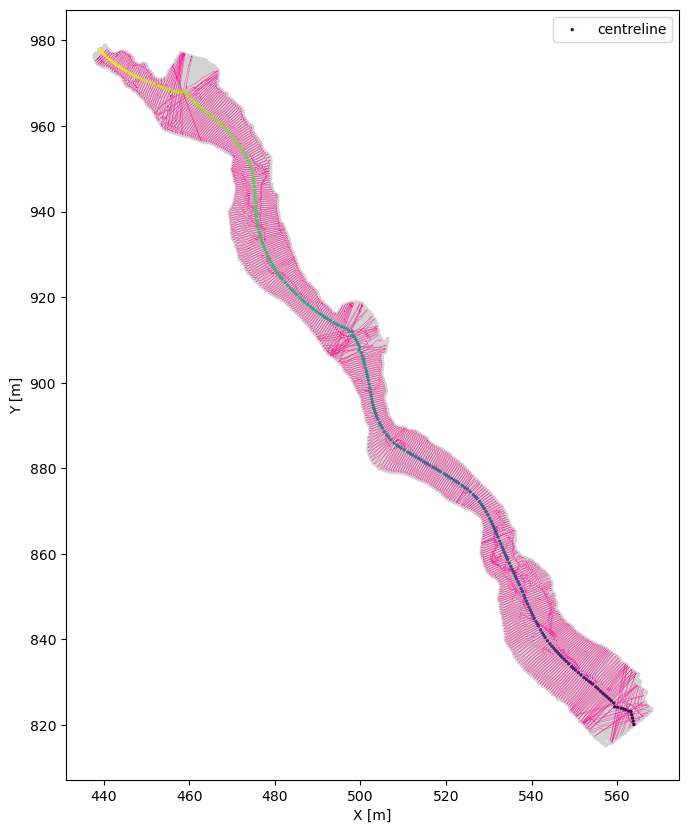

In [12]:
fig, ax = plt.subplots(figsize=(10, 10))

ax.scatter(*mesh_data[::100, [0,1]].T, color = "lightgrey", s = 2)

#ax.plot(*centreline[:, [0,1]].T, zorder = 100, lw = 2, label = "centreline")
ax.scatter(*centreline[:, [0,1]].T, c = np.arange(len(centreline)),zorder = 100,s = 2, label = "centreline")


for section in sections:
    if section is not None:
        ax.plot(*section[:, [0,1]].T, color = "deeppink", lw = 0.25)

ax.set_aspect("equal")
ax.legend()
ax.set_ylabel("Y [m]")
ax.set_xlabel("X [m]")

#plt.savefig("./temp/fauxMonnayeurs_sections_plan.png")

Text(0.5, 0, 'X [m]')

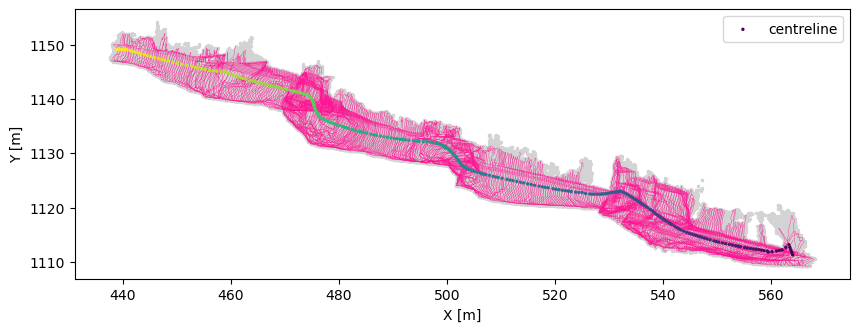

In [13]:
fig, ax = plt.subplots(figsize=(10,10))

ax.scatter(*mesh_data[::100, [0,2]].T, color = "lightgrey", s = 2)

#ax.plot(*centreline[:, [0,1]].T, zorder = 100, lw = 2, label = "centreline")
ax.scatter(*centreline[:, [0,2]].T, c = np.arange(len(centreline)),zorder = 100,s = 2, label = "centreline")


for section in sections:
    if section is not None:
        ax.plot(*section[:, [0,2]].T, color = "deeppink", lw = 0.25)

ax.set_aspect("equal")
ax.legend()
ax.set_ylabel("Y [m]")
ax.set_xlabel("X [m]")

#plt.savefig("./temp/fauxMonnayeurs_sections_profile.png")

In [14]:
run_main_loop = True

if run_main_loop == True:
    
    for idx in range(len(passages_filepaths)):

        try:
        
            plymesh = passages_filepaths[idx]
            stlmesh = plymesh[:-4] +".stl"
            assert exists(stlmesh)
            mesh_data = mesh.Mesh.from_file(stlmesh)

            adjacent_triangles_filepath = stlmesh[:-4]+ "_adjacent_triangles.txt"
            assert exists(adjacent_triangles_filepath)
            adjacent_triangles = np.loadtxt(adjacent_triangles_filepath).astype(int)

            # here's a quick test to show that the adjacency matrix file is probably fine.
            assert len(adjacent_triangles) == len(mesh_data.vectors)

            centreline_filepath = join(split(stlmesh)[0][:-4], "geometric_descriptors", split(stlmesh)[1][:-12] + "centreline.txt")
            assert exists(centreline_filepath)
            centreline = np.loadtxt(centreline_filepath, skiprows=1)

            interp_centreline, curvilinear_coords, normed_vectors = return_centreline_parametrisation(centreline, dt=0.5)

            sections_directory = join(split(stlmesh)[0][:-4], "geometric_descriptors", "sections")
            
            if exists(sections_directory):
                print("sections_directory already exists")
            else:
                makedirs(sections_directory)

            keep_sections = False

            if keep_sections == False:
                rmtree(sections_directory)
                makedirs(sections_directory)

            # we iterated over every point of the centreline. 
            for c, (P, nP) in tqdm(enumerate(zip(interp_centreline[1:-1], normed_vectors)), total=len(normed_vectors)):
                
                section_filepath = join(sections_directory, f"s{c}.txt")
                
                if exists(section_filepath) and keep_sections:
                    thesection = np.loadtxt(section_filepath, skiprows=1)
                else:
                    thesection = mesh_intersect(mesh_data, P, nP)[0]
                    np.savetxt(section_filepath, thesection, header="X, Y, Z")
        
        except AssertionError:
            print(f"not all files exist yet for index {idx}!")
            pass


sections_directory already exists


100%|██████████████████████████████████████████████████████████████████████████████████| 97/97 [00:29<00:00,  3.31it/s]


sections_directory already exists


100%|████████████████████████████████████████████████████████████████████████████████| 355/355 [04:19<00:00,  1.37it/s]


sections_directory already exists


...

sections_directory already exists


100%|████████████████████████████████████████████████████████████████████████████████| 287/287 [04:34<00:00,  1.04it/s]


sections_directory already exists


 79%|██████████████████████████████████████████████████████████████▌                | 901/1137 [46:03<12:03,  3.07s/it]


KeyboardInterrupt: 